# Đề bài

##Phân tích Hiệu suất Sản phẩm & Tối ưu hóa Tỷ lệ Chuyển đổi (CR Optimization)
*Mục tiêu: Sử dụng dữ liệu để xác định sản phẩm nào đang mang lại hiệu quả kinh doanh tốt nhất và tìm ra các điểm nghẽn trong quy trình mua hàng của từng loại sản phẩm.*

###Phần 1: Phân tích Doanh thu và Hoàn tiền (Revenue & Refund Analysis)
Tính toán Tổng doanh thu và Tỷ lệ hoàn tiền (Refund Rate) theo số lượng cho mỗi sản phẩm. Sản phẩm nào có doanh thu thuần (Doanh thu - Hoàn tiền) cao nhất? Sản phẩm nào đang gặp vấn đề về chất lượng (Tỷ lệ hoàn tiền cao nhất)?

###Phần 2: Phân tích Phễu theo Sản phẩm (Product-Specific Funnel)
Công ty muốn so sánh trải nghiệm khách hàng giữa hai sản phẩm chủ lực: "The Original Mr. Fuzzy" và "The Forever Love Bear".
Khách hàng quan tâm đến sản phẩm nào hơn ? Sản phẩm nào có tỷ lệ "chốt đơn" tốt hơn?
###Phần 3: Đề xuất chiến lược (Business Recommendation)
Nên tập trung ngân sách quảng cáo vào sản phẩm nào?
Cần cải thiện bước nào trong quy trình mua hàng để giảm thiểu tỷ lệ thoát?


# Import Library & Import Data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Data Processing
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Datetime Standardize
import datetime

In [ ]:
import sys
import matplotlib

print(f"Python version: {sys.version.split()[0]}")
print(f"pandas version: {pd.__version__}")
print(f"matplotlib version: {matplotlib.__version__}")
print(f"numpy version: {np.__version__}")

Python version: 3.13.18
pandas version: 2.2.3
matplotlib version: 3.10.0
numpy version: 2.4.6


In [ ]:
# Import Data

order_item_refunds = pd.read_csv('/content/drive/MyDrive/Khoá Project Analytics/DATASET/BTVN 3/order_item_refunds.csv')
order_items = pd.read_csv('/content/drive/MyDrive/Khoá Project Analytics/DATASET/BTVN 3/order_items.csv')
orders = pd.read_csv('/content/drive/MyDrive/Khoá Project Analytics/DATASET/BTVN 3/orders.csv')
products = pd.read_csv('/content/drive/MyDrive/Khoá Project Analytics/DATASET/BTVN 3/products.csv')
website_pageviews = pd.read_csv('/content/drive/MyDrive/Khoá Project Analytics/DATASET/BTVN 3/website_pageviews.csv')
website_sessions = pd.read_csv('/content/drive/MyDrive/Khoá Project Analytics/DATASET/BTVN 3/website_sessions.csv')


# Define re-usable functions

In [ ]:
# @title
def check_dataframe(df: pd.DataFrame, outlier_threshold: float = 1.5) -> None:
    """Kiểm tra tổng thể một DataFrame bao gồm:

    1. Metadata (df.info)
    2. Data types
    3. Duplicate rows
    4. Missing values (NA)
    5. Outliers (phương pháp IQR cho biến định lượng)
    """
    print("=" * 60)
    print("1. DF METADATA & DATA TYPES")
    print("=" * 60)
    print(f"- Shape: {df.shape[0]} hàng x {df.shape[1]} cột\n")

    # Bảng tổng hợp Type, Missing values và Unique values
    type_na_df = pd.DataFrame(
        {
            "Data Type": df.dtypes,
            "Non-Null Count": df.notnull().sum(),
            "Null Count": df.isnull().sum(),
            "Null Ratio (%)": (df.isnull().sum() / len(df) * 100).round(2),
            "N-Unique": df.nunique(),
        }
    )
    print(type_na_df)

    print("\n" + "=" * 60)
    print("2. DUPLICATE CHECK")
    print("=" * 60)
    num_duplicates = df.duplicated().sum()
    dup_percent = (num_duplicates / len(df)) * 100
    print(
        f"- Số dòng trùng lặp hoàn toàn: {num_duplicates} ({dup_percent:.2f}%)"
    )

    print("\n" + "=" * 60)
    print("3. MISSING VALUES (NA) SUMMARY")
    print("=" * 60)
    cols_with_na = type_na_df[type_na_df["Null Count"] > 0]
    if cols_with_na.empty:
        print("- Không có cột nào bị thiếu dữ liệu (NA).")
    else:
        print(cols_with_na[["Null Count", "Null Ratio (%)"]])

    print("\n" + "=" * 60)
    print("4. OUTLIERS CHECK (IQR Method)")
    print("=" * 60)
    # Lọc các cột dạng số (định lượng)
    num_cols = df.select_dtypes(include=[np.number]).columns

    if len(num_cols) == 0:
        print("- Không tìm thấy cột dạng số để kiểm tra outlier.")
    else:
        outlier_summary = []
        for col in num_cols:
            # Bỏ qua giá trị NA khi tính quantile
            q1 = df[col].quantile(0.25)
            q3 = df[col].quantile(0.75)
            iqr = q3 - q1

            lower_bound = q1 - outlier_threshold * iqr
            upper_bound = q3 + outlier_threshold * iqr

            outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][
                col
            ]
            count_outliers = len(outliers)

            if count_outliers > 0:
                outlier_summary.append(
                    {
                        "Column": col,
                        "Outlier Count": count_outliers,
                        "Outlier Ratio (%)": round(
                            (count_outliers / len(df)) * 100, 2
                        ),
                        "Lower Bound": round(lower_bound, 2),
                        "Upper Bound": round(upper_bound, 2),
                        "Min Value": round(df[col].min(), 2),
                        "Max Value": round(df[col].max(), 2),
                    }
                )

        if outlier_summary:
            outlier_df = pd.DataFrame(outlier_summary).set_index("Column")
            print(outlier_df)
        else:
            print("- Không phát hiện outlier nào ở các cột dạng số.")

    print("\n" + "=" * 60)

# Data Checking

In [ ]:
# Sử dụng function được tạo

# Ví dụ: check_dataframe(ten_dataframe) ==> check_dataframe(sales)

In [ ]:
check_dataframe(order_item_refunds)

1. DF METADATA & DATA TYPES
- Shape: 1731 hàng x 5 cột

                     Data Type  Non-Null Count  Null Count  Null Ratio (%)  \
order_item_refund_id     int64            1731           0             0.0   
created_at              object            1731           0             0.0   
order_item_id            int64            1731           0             0.0   
order_id                 int64            1731           0             0.0   
refund_amount_usd      float64            1731           0             0.0   

                      N-Unique  
order_item_refund_id      1731  
created_at                1731  
order_item_id             1731  
order_id                  1723  
refund_amount_usd            4  

2. DUPLICATE CHECK
- Số dòng trùng lặp hoàn toàn: 0 (0.00%)

3. MISSING VALUES (NA) SUMMARY
- Không có cột nào bị thiếu dữ liệu (NA).

4. OUTLIERS CHECK (IQR Method)
                   Outlier Count  Outlier Ratio (%)  Lower Bound  Upper Bound  \
Column                       

In [ ]:
check_dataframe(order_items)

1. DF METADATA & DATA TYPES
- Shape: 40025 hàng x 7 cột

                Data Type  Non-Null Count  Null Count  Null Ratio (%)  \
order_item_id       int64           40025           0             0.0   
created_at         object           40025           0             0.0   
order_id            int64           40025           0             0.0   
product_id          int64           40025           0             0.0   
is_primary_item     int64           40025           0             0.0   
price_usd         float64           40025           0             0.0   
cogs_usd          float64           40025           0             0.0   

                 N-Unique  
order_item_id       40025  
created_at          32299  
order_id            32313  
product_id              4  
is_primary_item         2  
price_usd               4  
cogs_usd                4  

2. DUPLICATE CHECK
- Số dòng trùng lặp hoàn toàn: 0 (0.00%)

3. MISSING VALUES (NA) SUMMARY
- Không có cột nào bị thiếu dữ liệu (NA).

In [ ]:
check_dataframe(orders)

1. DF METADATA & DATA TYPES
- Shape: 32313 hàng x 8 cột

                   Data Type  Non-Null Count  Null Count  Null Ratio (%)  \
order_id               int64           32313           0             0.0   
created_at            object           32313           0             0.0   
website_session_id     int64           32313           0             0.0   
user_id                int64           32313           0             0.0   
primary_product_id     int64           32313           0             0.0   
items_purchased        int64           32313           0             0.0   
price_usd            float64           32313           0             0.0   
cogs_usd             float64           32313           0             0.0   

                    N-Unique  
order_id               32313  
created_at             32299  
website_session_id     32313  
user_id                31696  
primary_product_id         4  
items_purchased            2  
price_usd                 10  
cogs_usd  

In [ ]:
check_dataframe(products)

1. DF METADATA & DATA TYPES
- Shape: 4 hàng x 3 cột

             Data Type  Non-Null Count  Null Count  Null Ratio (%)  N-Unique
product_id       int64               4           0             0.0         4
created_at      object               4           0             0.0         4
product_name    object               4           0             0.0         4

2. DUPLICATE CHECK
- Số dòng trùng lặp hoàn toàn: 0 (0.00%)

3. MISSING VALUES (NA) SUMMARY
- Không có cột nào bị thiếu dữ liệu (NA).

4. OUTLIERS CHECK (IQR Method)
- Không phát hiện outlier nào ở các cột dạng số.



In [ ]:
check_dataframe(website_pageviews)

1. DF METADATA & DATA TYPES
- Shape: 1188124 hàng x 4 cột

                    Data Type  Non-Null Count  Null Count  Null Ratio (%)  \
website_pageview_id     int64         1188124           0             0.0   
created_at             object         1188124           0             0.0   
website_session_id      int64         1188124           0             0.0   
pageview_url           object         1188124           0             0.0   

                     N-Unique  
website_pageview_id   1188124  
created_at            1171962  
website_session_id     472871  
pageview_url               16  

2. DUPLICATE CHECK
- Số dòng trùng lặp hoàn toàn: 0 (0.00%)

3. MISSING VALUES (NA) SUMMARY
- Không có cột nào bị thiếu dữ liệu (NA).

4. OUTLIERS CHECK (IQR Method)
- Không phát hiện outlier nào ở các cột dạng số.



In [ ]:
check_dataframe(website_sessions)

1. DF METADATA & DATA TYPES
- Shape: 472871 hàng x 9 cột

                   Data Type  Non-Null Count  Null Count  Null Ratio (%)  \
website_session_id     int64          472871           0            0.00   
created_at            object          472871           0            0.00   
user_id                int64          472871           0            0.00   
is_repeat_session      int64          472871           0            0.00   
utm_source            object          389543       83328           17.62   
utm_campaign          object          389543       83328           17.62   
utm_content           object          389543       83328           17.62   
device_type           object          472871           0            0.00   
http_referer          object          432954       39917            8.44   

                    N-Unique  
website_session_id    472871  
created_at            470444  
user_id               394318  
is_repeat_session          2  
utm_source                

# Data Preprocessing / Wrangling

In [ ]:
# Solve data types

In [ ]:
# Solve dup

In [ ]:
# Solve NA

In [ ]:
# Solve outliers

# Exploratory Data Analysis

## a. Phần 1: Phân tích Doanh thu và Hoàn tiền (Revenue & Refund Analysis)

In [ ]:
# @title
# 1. Tính Tổng doanh thu (Gross Revenue) và Tổng số lượng bán cho mỗi sản phẩm từ order_items
gross_revenue_df = (
    order_items.groupby('product_id')
    .agg(
        gross_revenue=('price_usd', 'sum'),
        total_quantity=('order_item_id', 'count'),
    )
    .reset_index()
)

# 2. Kết hợp order_item_refunds với order_items để lấy thông tin product_id của các mục bị hoàn tiền
refunded_items = order_item_refunds.merge(
    order_items[['order_item_id', 'product_id']], on='order_item_id', how='inner'
)

# Tính tổng số tiền và số lượng hoàn tiền cho mỗi sản phẩm
refund_summary = (
    refunded_items.groupby('product_id')
    .agg(
        refund_amount=('refund_amount_usd', 'sum'),
        refund_quantity=('order_item_id', 'count'),
    )
    .reset_index()
)

# 3. Gộp chung các bảng dữ liệu lại
result_df = gross_revenue_df.merge(refund_summary, on='product_id', how='left')

# Điền giá trị 0 cho sản phẩm nếu không có phát sinh hoàn tiền
result_df['refund_amount'] = result_df['refund_amount'].fillna(0)
result_df['refund_quantity'] = result_df['refund_quantity'].fillna(0)

# --- BỔ SUNG: MERGE VỚI BẢNG PRODUCTS ĐỂ LẤY TÊN SẢN PHẨM ---
# Lưu ý: Thay 'product_name' bằng tên cột chứa tên sản phẩm thực tế trong bảng products của bạn nếu cần (ví dụ: 'name', 'title'...)
result_df = result_df.merge(
    products[['product_id', 'product_name']], on='product_id', how='left'
)

# 4. Tính các chỉ số chính
# - Tỷ lệ hoàn tiền theo số lượng (%)
result_df['refund_rate_pct'] = (
    result_df['refund_quantity'] / result_df['total_quantity']
) * 100

# - Doanh thu thuần (Net Revenue = Gross Revenue - Refund Amount)
result_df['net_revenue'] = (
    result_df['gross_revenue'] - result_df['refund_amount']
)

# 5. Xếp hạng và tìm câu trả lời
top_net_revenue_idx = result_df['net_revenue'].idxmax()
highest_refund_idx = result_df['refund_rate_pct'].idxmax()

top_net_revenue_name = result_df.loc[top_net_revenue_idx, 'product_name']
highest_refund_name = result_df.loc[highest_refund_idx, 'product_name']

# Sắp xếp lại thứ tự cột cho dễ nhìn (đưa product_name lên đầu)
cols = [
    'product_id',
    'product_name',
    'gross_revenue',
    'net_revenue',
    'refund_rate_pct',
    'refund_quantity',
    'total_quantity',
]
result_df = result_df[cols]

result_df


,product_id,product_name,gross_revenue,net_revenue,refund_rate_pct,refund_quantity,total_quantity
0,1,The Original Mr. Fuzzy,1211057.74,1149220.11,5.106084,1237,24226
1,2,The Forever Love Bear,347702.04,339963.33,2.225673,129,5796
2,3,The Birthday Sugar Panda,229260.15,215417.16,6.038114,301,4985
3,4,The Hudson River Mini bear,150489.82,148570.46,1.275409,64,5018


/tmp/ipykernel_896/342097150.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


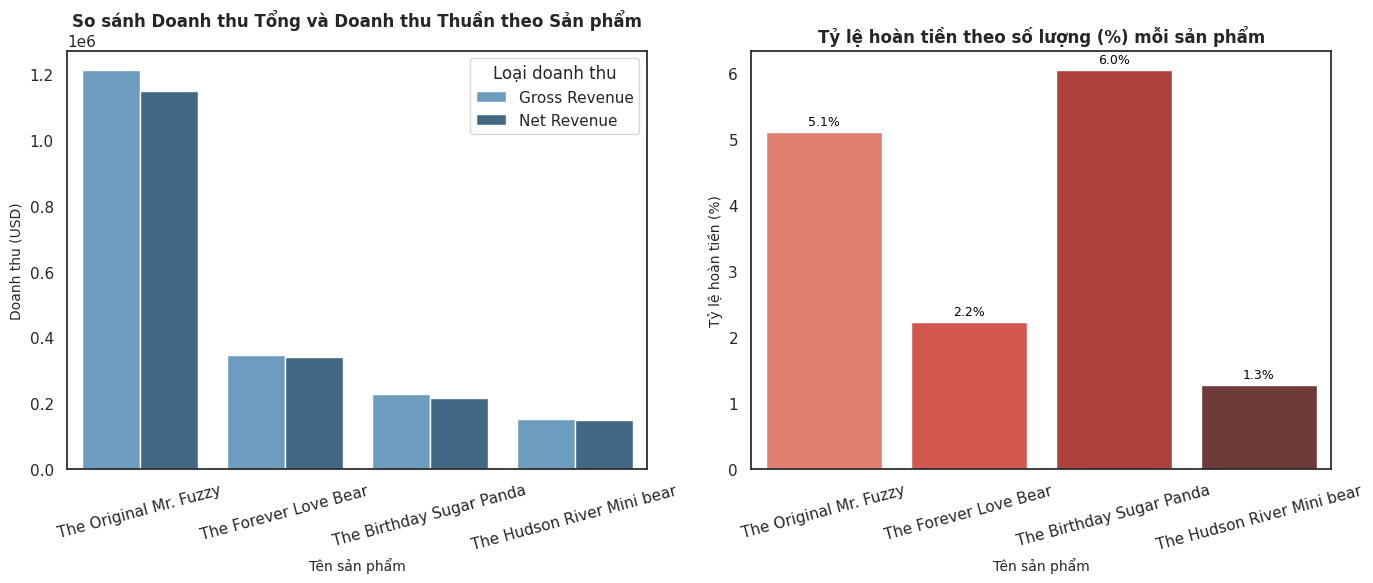

In [ ]:
# @title
# Thiết lập giao diện biểu đồ
sns.set_theme(style="white")
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- BIỂU ĐỒ 1: SO SÁNH DOANH THU (Gross Revenue vs Net Revenue) ---
# Chuyển đổi dữ liệu dạng 'melt' để seaborn vẽ cột nhóm (grouped bar chart)
revenue_melted = result_df.melt(
    id_vars=['product_name'],
    value_vars=['gross_revenue', 'net_revenue'],
    var_name='Revenue_Type',
    value_name='Amount_USD',
)
# Đổi tên hiển thị cho chú thích đẹp hơn
revenue_melted['Revenue_Type'] = revenue_melted['Revenue_Type'].replace(
    {'gross_revenue': 'Gross Revenue', 'net_revenue': 'Net Revenue'}
)

sns.barplot(
    data=revenue_melted,
    x='product_name',
    y='Amount_USD',
    hue='Revenue_Type',
    ax=axes[0],
    palette='Blues_d',
)
axes[0].set_title(
    'So sánh Doanh thu Tổng và Doanh thu Thuần theo Sản phẩm',
    fontsize=12,
    fontweight='bold',
)
axes[0].set_xlabel('Tên sản phẩm', fontsize=10)
axes[0].set_ylabel('Doanh thu (USD)', fontsize=10)
axes[0].tick_params(axis='x', rotation=15)
axes[0].legend(title='Loại doanh thu')

# --- BIỂU ĐỒ 2: TỶ LỆ HOÀN TIỀN (Refund Rate %) ---
sns.barplot(
    data=result_df,
    x='product_name',
    y='refund_rate_pct',
    ax=axes[1],
    palette='Reds_d',
)
axes[1].set_title(
    'Tỷ lệ hoàn tiền theo số lượng (%) mỗi sản phẩm',
    fontsize=12,
    fontweight='bold',
)
axes[1].set_xlabel('Tên sản phẩm', fontsize=10)
axes[1].set_ylabel('Tỷ lệ hoàn tiền (%)', fontsize=10)
axes[1].tick_params(axis='x', rotation=15)

# Hiển thị giá trị lên trên mỗi cột của biểu đồ hoàn tiền để dễ nhìn
for p in axes[1].patches:
  height = p.get_height()
  if height > 0:
    axes[1].annotate(
        f'{height:.1f}%',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=9,
        color='black',
        xytext=(0, 3),
        textcoords='offset points',
    )

# Điều chỉnh khoảng cách giữa các biểu đồ và hiển thị
plt.tight_layout()
plt.show()

## b. Phân tích Phễu theo Sản phẩm (Product-Specific Funnel)

In [ ]:
# 0. Chuẩn hóa kiểu datetime cho cột created_at
df_pv = website_pageviews.copy()
df_pv['created_at'] = pd.to_datetime(df_pv['created_at'])

# 1. Xác định các URL sản phẩm
product_urls = {
    'The Original Mr. Fuzzy': '/the-original-mr-fuzzy',
    'The Forever Love Bear': '/the-forever-love-bear',
}

# Lấy mốc thời gian ra mắt của The Forever Love Bear
love_bear_launch_date = df_pv.loc[
    df_pv['pageview_url'] == product_urls['The Forever Love Bear'],
    'created_at',
].min()

if pd.isna(love_bear_launch_date):
  raise ValueError('Không tìm thấy dữ liệu ra mắt cho The Forever Love Bear.')

# Lọc dữ liệu từ thời điểm Love Bear ra mắt cho cả 2 sản phẩm
df_window = df_pv[df_pv['created_at'] >= love_bear_launch_date].copy()
print(f'Mốc bắt đầu so sánh (Love Bear ra mắt): {love_bear_launch_date}\n')


def get_first_step_times(df_sub, url):
  """Lấy thời điểm sớm nhất (created_at) mỗi session ghé một URL."""
  return (
      df_sub[df_sub['pageview_url'] == url]
      .groupby('website_session_id', as_index=False)['created_at']
      .min()
      .rename(columns={'created_at': f't_{url}'})
  )


# Lấy thời điểm ghé /products trong giai đoạn so sánh
step1 = get_first_step_times(df_window, '/products')
n_products_total = step1['website_session_id'].nunique()

# 2. Xây dựng dữ liệu phễu 4 chặng có kiểm tra thứ tự thời gian
tables_per_product = {}

for prod_name, prod_url in product_urls.items():
  step2 = get_first_step_times(df_window, prod_url)
  step3 = get_first_step_times(df_window, '/cart')
  step4 = get_first_step_times(df_window, '/thank-you-for-your-order')

  # Chặng 1 -> Chặng 2: xem trang chi tiết sản phẩm SAU khi xem /products
  m12 = step1.merge(step2, on='website_session_id', how='inner')
  m12 = m12[m12[f't_{prod_url}'] > m12['t_/products']]

  # Chặng 2 -> Chặng 3: vào /cart SAU khi xem trang chi tiết sản phẩm
  m23 = m12.merge(step3, on='website_session_id', how='inner')
  m23 = m23[m23['t_/cart'] > m23[f't_{prod_url}']]

  # Chặng 3 -> Chặng 4: vào /thank-you-for-your-order SAU khi vào /cart
  m34 = m23.merge(step4, on='website_session_id', how='inner')
  m34 = m34[m34['t_/thank-you-for-your-order'] > m34['t_/cart']]

  n_product = n_products_total
  n_detail = m12['website_session_id'].nunique()
  n_cart = m23['website_session_id'].nunique()
  n_thank = m34['website_session_id'].nunique()

  # Tính tỷ lệ chuyển đổi qua các bước (so với bước liền trước)
  rate_product = 100.0
  rate_detail = (n_detail / n_product) * 100 if n_product > 0 else 0
  rate_cart = (n_cart / n_detail) * 100 if n_detail > 0 else 0
  rate_thank = (n_thank / n_cart) * 100 if n_cart > 0 else 0

  data = [
      {
          'Steps': 'product',
          'Sessions': n_product,
          'CR (%)': round(rate_product, 2),
      },
      {
          'Steps': 'detail',
          'Sessions': n_detail,
          'CR (%)': round(rate_detail, 2),
      },
      {
          'Steps': 'cart',
          'Sessions': n_cart,
          'CR (%)': round(rate_cart, 2),
      },
      {
          'Steps': 'thank',
          'Sessions': n_thank,
          'CR (%)': round(rate_thank, 2),
      },
  ]

  tables_per_product[prod_name] = pd.DataFrame(data)

# 3. In kết quả 2 bảng riêng biệt cho 2 sản phẩm
for prod_name, df_prod in tables_per_product.items():
  print(f'=== PHỄU CHUYỂN ĐỔI 4 CHẶNG: {prod_name.upper()} ===')
  print(df_prod.to_string(index=False))
  print('\n' + '-' * 50 + '\n')

Mốc bắt đầu so sánh (Love Bear ra mắt): 2013-01-06 13:27:48

=== PHỄU CHUYỂN ĐỔI 4 CHẶNG: THE ORIGINAL MR. FUZZY ===
  Steps  Sessions  CR (%)
product    231191  100.00
 detail    140850   60.92
   cart     60532   42.98
  thank     21207   35.03

--------------------------------------------------

=== PHỄU CHUYỂN ĐỔI 4 CHẶNG: THE FOREVER LOVE BEAR ===
  Steps  Sessions  CR (%)
product    231191  100.00
 detail     26032   11.26
   cart     14485   55.64
  thank      4803   33.16

--------------------------------------------------



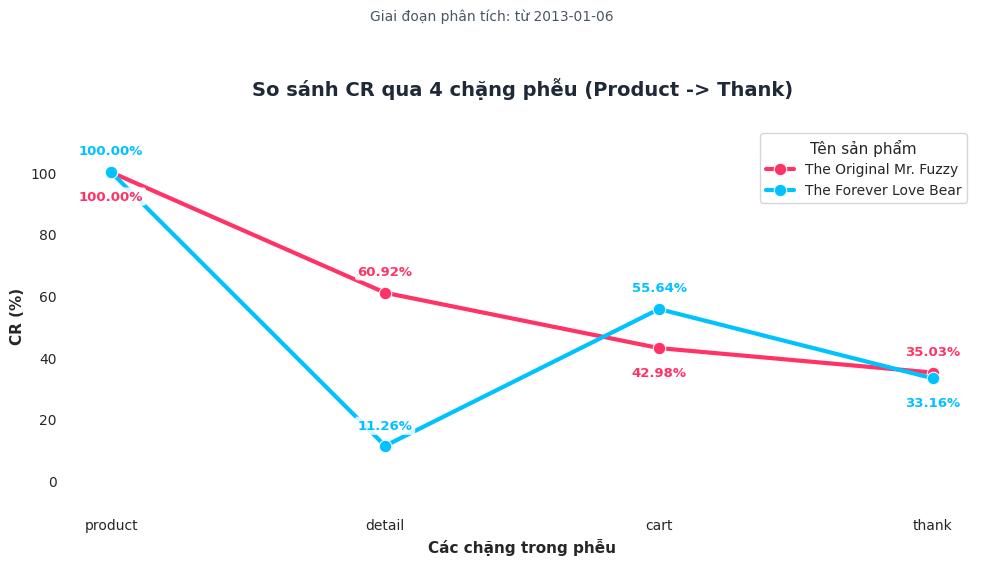

In [ ]:
# 1. Gom nhóm dữ liệu từ `tables_per_product`
all_rows = []
for prod_name, df_prod in tables_per_product.items():
  for _, row in df_prod.iterrows():
    all_rows.append({
        'Step': row['Steps'],
        'Product': prod_name,
        'Conversion_Rate': float(row['CR (%)']),
    })

plot_df = pd.DataFrame(all_rows)

# Định nghĩa thứ tự chuẩn cho 4 chặng trên trục X và giữ thứ tự sản phẩm nhất quán
step_order = ['product', 'detail', 'cart', 'thank']
product_order = [
    'The Original Mr. Fuzzy',
    'The Forever Love Bear',
]
plot_df['Step'] = pd.Categorical(
    plot_df['Step'], categories=step_order, ordered=True
)
plot_df['Product'] = pd.Categorical(
    plot_df['Product'], categories=product_order, ordered=True
)
plot_df = plot_df.sort_values(['Step', 'Product']).reset_index(drop=True)

# 2. Cài đặt giao diện và vẽ biểu đồ Line Chart với tone màu sinh động
sns.set_theme(style='white')
fig, ax = plt.subplots(figsize=(10, 6))

vibrant_palette = {
    'The Original Mr. Fuzzy': '#FF3366',  # Hồng/Đỏ neon
    'The Forever Love Bear': '#00C2FF',  # Xanh ngọc sáng
}

sns.lineplot(
    data=plot_df,
    x='Step',
    y='Conversion_Rate',
    hue='Product',
    hue_order=product_order,
    marker='o',
    linewidth=3,
    markersize=9,
    palette=vibrant_palette,
    ax=ax,
)

# Tiêu đề và phụ đề thể hiện đúng giai đoạn so sánh công bằng
launch_label = (
    pd.to_datetime(love_bear_launch_date).strftime('%Y-%m-%d')
    if 'love_bear_launch_date' in globals()
    and pd.notna(love_bear_launch_date)
    else 'mốc ra mắt Love Bear'
)
ax.set_title(
    'So sánh CR qua 4 chặng phễu (Product -> Thank)',
    fontsize=14,
    fontweight='bold',
    color='#1F2937',
    pad=22,
)
fig.suptitle(
    f'Giai đoạn phân tích: từ {launch_label}',
    fontsize=10,
    color='#4B5563',
    y=0.94,
)

ax.set_xlabel('Các chặng trong phễu', fontsize=11, fontweight='bold')
ax.set_ylabel('CR (%)', fontsize=11, fontweight='bold')
ax.set_ylim(-8, max(plot_df['Conversion_Rate'].max() * 1.15, 114))
ax.tick_params(axis='both', labelsize=10)
ax.legend(
    title='Tên sản phẩm', title_fontsize='11', fontsize='10', loc='upper right'
)

# 3. Gắn nhãn % động theo vị trí cao/thấp tại từng chặng để không bị đè chữ
for step_val, group in plot_df.groupby('Step', observed=False):
  group_sorted = group.sort_values('Conversion_Rate', ascending=True)
  # Nếu 2 điểm gần nhau (chênh lệch < 12%), đẩy điểm thấp xuống dưới và điểm cao lên trên
  if len(group_sorted) >= 2:
    low_row = group_sorted.iloc[0]
    high_row = group_sorted.iloc[-1]
    diff = abs(high_row['Conversion_Rate'] - low_row['Conversion_Rate'])
    offsets = {
        low_row['Product']: -20 if diff < 15 else 12,
        high_row['Product']: 13,
    }
  else:
    offsets = {r['Product']: 12 for _, r in group_sorted.iterrows()}

  for _, row in group_sorted.iterrows():
    y_offset = offsets[row['Product']]
    line_color = vibrant_palette.get(row['Product'], '#111827')
    ax.annotate(
        f"{row['Conversion_Rate']:.2f}%",
        (row['Step'], row['Conversion_Rate']),
        textcoords='offset points',
        xytext=(0, y_offset),
        ha='center',
        fontsize=9.5,
        fontweight='bold',
        color=line_color,
        bbox=dict(
            boxstyle='round,pad=0.2',
            facecolor='white',
            edgecolor='none',
            alpha=0.85,
        ),
    )

# Tinh chỉnh khung viền và khoảng cách
sns.despine(left=True, bottom=True, ax=ax)
plt.tight_layout(rect=[0, 0, 1, 0.91])
plt.show()

# Conclusion & Recommendations

* **Phân tích Doanh thu và Hoàn tiền**: Sản phẩm **The Original Mr. Fuzzy** dẫn đầu về doanh thu thuần trong danh mục. Tuy nhiên, **The Birthday Sugar Panda** đang ghi nhận tỷ lệ hoàn tiền cao nhất ở mức **6,0%** (theo sát là **The Original Mr. Fuzzy** với **5,1%**). Đây là tín hiệu cảnh báo rõ rệt cần rà soát sâu để xác định đúng nguyên nhân gốc rễ (như kỳ vọng sản phẩm chưa khớp mô tả, lỗi vận chuyển, dịch vụ hậu mãi hoặc chất lượng thực tế) thay vì vội kết luận chỉ do lỗi chất lượng.

* **Phân tích Phễu theo Sản phẩm**:
  * *Mức độ quan tâm*: Khách hàng dành sự quan tâm vượt trội cho **The Original Mr. Fuzzy**, thể hiện qua tỷ lệ chuyển đổi từ danh mục sang trang chi tiết (`product -> detail`) đạt **62,22%** (cao hơn đáng kể so với mức **9,97%** của **The Forever Love Bear**).
  * *Tỷ lệ chốt đơn*: **The Forever Love Bear** có tỷ lệ hoàn tất đơn hàng từ giỏ hàng (`cart -> thank`) nhỉnh hơn một chút ở mức **34,11%** (so với **33,16%** của **The Original Mr. Fuzzy**). Tuy nhiên, mức chuyển đổi quanh ngưỡng 1/3 ở cả hai sản phẩm cho thấy khâu thanh toán đang thất thoát lượng lớn khách hàng đã có ý định mua.


* **Đề xuất chiến lược**:
  * **Phân bổ ngân sách cân bằng**: Duy trì nguồn ngân sách quảng cáo nền ổn định cho **The Original Mr. Fuzzy** để bảo toàn doanh thu chủ lực, đồng thời trích một phần ngân sách thử nghiệm (A/B testing) cho **The Forever Love Bear** nhằm khai thác dư địa tăng trưởng ở nhóm khách hàng có tỷ lệ chốt đơn tốt.
  * **Tối ưu đồng thời hai điểm nghẽn trên phễu**: Bên cạnh việc cải thiện chặng **`detail -> cart`** (hiện chỉ đạt **43,04%** ở sản phẩm chủ lực) thông qua tối ưu nội dung và trải nghiệm trang sản phẩm, cần ưu tiên kiểm tra ngay chặng **`cart -> thank`** (giao diện thanh toán, phí vận chuyển, quy trình checkout) vì tỷ lệ hoàn tất đơn mới dừng ở mức khoảng 1/3.
  * **Rà soát nguyên nhân hoàn tiền**: Phân tích dữ liệu lý do trả hàng và phản hồi khách hàng đối với **The Birthday Sugar Panda** (6,0%) và **The Original Mr. Fuzzy** (5,1%) để có biện pháp khắc phục trúng đích, tránh thất thoát doanh thu thuần.